In [1]:
from matplotlib.ticker import FuncFormatter

import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Splitting the Data for Weak Scaling Experiment

In [2]:
'''
FRACTIONS = [64, 16, 4]
SEED = 42

path = "ml-32m/ratings.csv" 
out_dir = os.path.dirname(os.path.abspath(path))

df = pd.read_csv(path, dtype={"userId": "int32", "movieId": "int32",
                              "rating": "float32", "timestamp": "int64"})
total = len(df)

# ratings per user, and one random order of the users
counts = df.groupby("userId").size()
order = np.random.default_rng(SEED).permutation(counts.index.to_numpy())
cum = counts.loc[order].cumsum().to_numpy()

print(f"full data: {counts.size} users, {total} ratings, {df.movieId.nunique()} movies")
for d in FRACTIONS:
    n = int(np.searchsorted(cum, total / d)) + 1      # users needed to reach 1/d of the ratings
    sub = df[df.userId.isin(order[:n])]                # whole users, original row order
    out = os.path.join(os.path.dirname(path), f"ratings_1of{d}.csv")
    sub.to_csv(out, index=False, float_format="%.1f")
    print(f"{out}: {n} users, {len(sub)} ratings ({len(sub)/total:.4f} of all), "
          f"{sub.movieId.nunique()} movies, median {int(counts.loc[order[:n]].median())} ratings/user")
'''

full data: 200948 users, 32000204 ratings, 84432 movies
ml-32m\ratings_1of64.csv: 3158 users, 500051 ratings (0.0156 of all), 21027 movies, median 75 ratings/user
ml-32m\ratings_1of16.csv: 12833 users, 2000037 ratings (0.0625 of all), 33929 movies, median 73 ratings/user
ml-32m\ratings_1of4.csv: 50353 users, 8000061 ratings (0.2500 of all), 56217 movies, median 72 ratings/user


### Data Analysis for Experiments

In [2]:
df = pd.read_csv("all_results_long.csv")
df

,experiment,program,uses_MPI,uses_OpenMP_threads,uses_GPU,mpi_ranks,openmp_threads_per_rank,cpu_cores,gpus,dataset,...,iter_time_s,compute_s,comm_s,gpu_transfer_s,imbalance,train_rmse,test_rmse,load_s,distribute_s,source_file
0,serial baseline,serial,no,no,no,1,1,1,0,full ratings,...,1.8001,1.8001,0.0,0.0000,1.0,0.860943,0.880731,15.197,0.000,results_serial.txt
1,serial baseline,serial,no,no,no,1,1,1,0,full ratings,...,1.7987,1.7987,0.0,0.0000,1.0,0.833025,0.851014,15.197,0.000,results_serial.txt
2,serial baseline,serial,no,no,no,1,1,1,0,full ratings,...,1.8139,1.8139,0.0,0.0000,1.0,0.799866,0.823096,15.197,0.000,results_serial.txt
3,serial baseline,serial,no,no,no,1,1,1,0,full ratings,...,1.7949,1.7949,0.0,0.0000,1.0,0.785612,0.812166,15.197,0.000,results_serial.txt
4,serial baseline,serial,no,no,no,1,1,1,0,full ratings,...,1.7995,1.7995,0.0,0.0000,1.0,0.778136,0.806695,15.197,0.000,results_serial.txt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
215,GPU test,MPI + GPU (OpenMP offload),yes,no,yes,1,1,1,1,full ratings,...,0.5693,0.5665,0.0,0.0028,1.0,0.773695,0.803581,17.656,0.407,gpu_1.txt
216,GPU test,MPI + GPU (OpenMP offload),yes,no,yes,1,1,1,1,full ratings,...,0.5680,0.5653,0.0,0.0028,1.0,0.770923,0.801733,17.656,0.407,gpu_1.txt
217,GPU test,MPI + GPU (OpenMP offload),yes,no,yes,1,1,1,1,full ratings,...,0.5694,0.5666,0.0,0.0028,1.0,0.769134,0.800602,17.656,0.407,gpu_1.txt
218,GPU test,MPI + GPU (OpenMP offload),yes,no,yes,1,1,1,1,full ratings,...,0.5677,0.5649,0.0,0.0028,1.0,0.767973,0.799903,17.656,0.407,gpu_1.txt


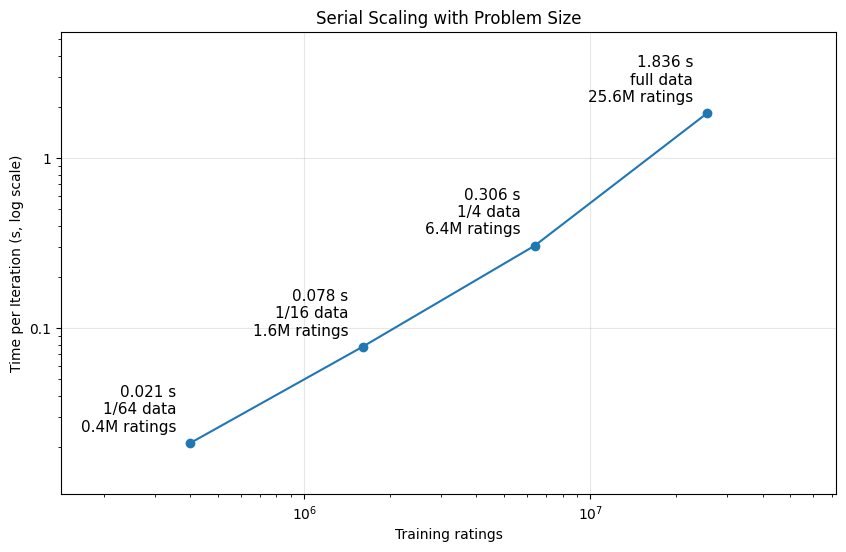

In [3]:
# serial scaling runs, average the runs
serial = df[(df["experiment"] == "serial scaling")]
serial = serial.groupby(["train_ratings", "dataset"], as_index=False)["iter_time_s"].mean()

plt.figure(figsize=(10, 6))
plt.plot(serial["train_ratings"], serial["iter_time_s"], marker="o")

# label each point: time, share of the data, training ratings
for x, y, ds in zip(serial["train_ratings"], serial["iter_time_s"], serial["dataset"]):
    share = ds.replace(" of ratings", "").replace(" ratings", "")
    text = f"{y:.3f} s\n{share} data\n{x/1e6:.1f}M ratings"
    plt.annotate(text, (x, y), textcoords="offset points", xytext=(-10, 6),
                 ha="right", va="bottom", fontsize=11)
    

plt.yscale("log")
plt.xscale("log")
plt.margins(x=0.25)
plt.ylim(bottom=serial["iter_time_s"].min() / 2, top=serial["iter_time_s"].max() * 3)
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))
plt.xlabel("Training ratings")
plt.ylabel("Time per Iteration (s, log scale)")
plt.title("Serial Scaling with Problem Size")
plt.grid(True, alpha=0.3)
#plt.savefig("serial_scaling.png", dpi=200, bbox_inches="tight")
plt.show()

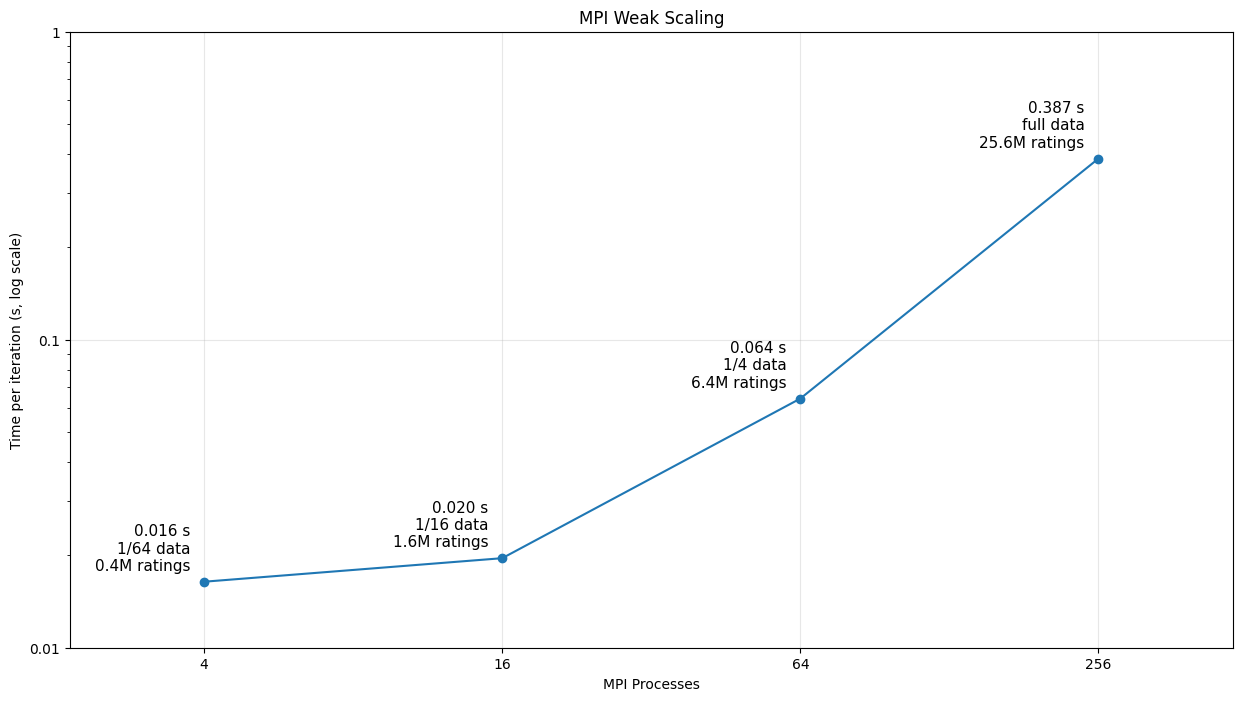

In [4]:
# MPI weak scaling runs, average the runs
mpi_weak = df[(df["experiment"] == "weak scaling")]
mpi_weak = mpi_weak.groupby("mpi_ranks", as_index=False).agg(iter_time_s=("iter_time_s", "mean"),
                                                             dataset=("dataset", "first"),
                                                             train_ratings=("train_ratings", "first"))

plt.figure(figsize=(15, 8))
plt.plot(mpi_weak["mpi_ranks"], mpi_weak["iter_time_s"], marker="o")

# label each dot: time, share of the data, training ratings (processes are on the x-axis)
for p, y, ds, r in zip(mpi_weak["mpi_ranks"], mpi_weak["iter_time_s"], mpi_weak["dataset"], mpi_weak["train_ratings"]):
    share = ds.replace(" of ratings", "").replace(" ratings", "")
    text = f"{y:.3f} s\n{share} data\n{r/1e6:.1f}M ratings"
    plt.annotate(text, (p, y), textcoords="offset points", xytext=(-10, 6),
                 ha="right", va="bottom", fontsize=11)

plt.yscale("log")
plt.xscale("log", base=2)
plt.xticks(mpi_weak["mpi_ranks"], mpi_weak["mpi_ranks"])
plt.yticks([0.01, 0.1, 1])
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))

plt.margins(x=0.15)
plt.ylim(bottom=0.01, top=1)
plt.xlabel("MPI Processes")
plt.ylabel("Time per iteration (s, log scale)")
plt.title("MPI Weak Scaling")
plt.grid(True, alpha=0.3)
#plt.savefig("mpi_weak_scaling.png", dpi=200, bbox_inches="tight")
plt.show()

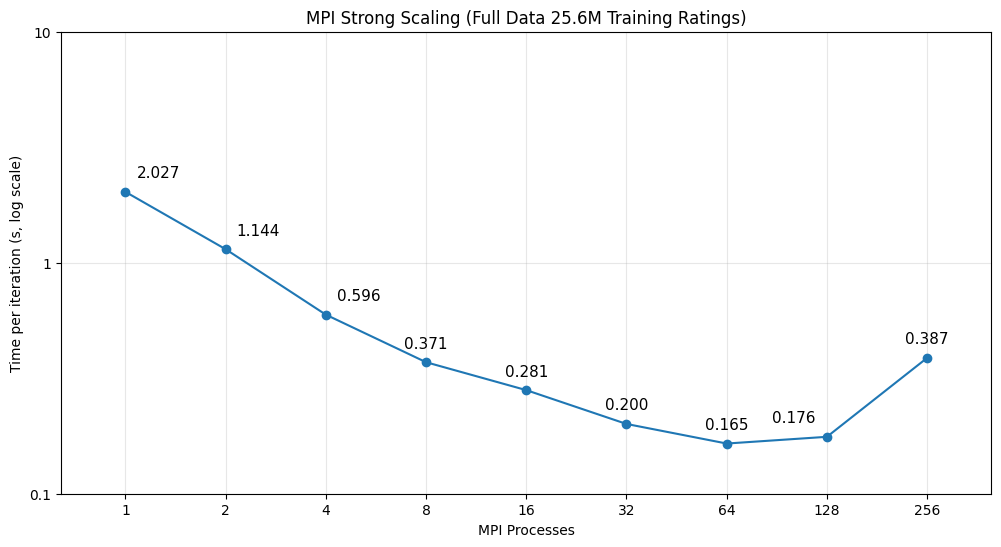

In [5]:
# MPI strong scaling runs (full data)
mpi_strong = df[(df["experiment"] == "strong scaling")]
mpi_strong = mpi_strong.groupby("mpi_ranks", as_index=False)[["iter_time_s", "compute_s", "comm_s"]].mean()
#mpi_strong = mpi_strong.groupby("mpi_ranks", as_index=False)["iter_time_s"].mean()
#mpi_strong["speedup"] = mpi_strong["iter_time_s"].iloc[0] / mpi_strong["iter_time_s"]      # vs 1 process

plt.figure(figsize=(12, 6))
plt.plot(mpi_strong["mpi_ranks"], mpi_strong["iter_time_s"], marker="o")

# label each dot with its time and speedup, placed so labels stay off the line and apart:
#   1-4: upper right (the line falls away)   128: upper left (the line rises after it)   others: above
for p, y in zip(mpi_strong["mpi_ranks"], mpi_strong["iter_time_s"]):
    if p <= 4:
        offset, ha, va = (8, 8), "left", "bottom"
    elif p == 128:
        offset, ha, va = (-8, 8), "right", "bottom"
    else:
        offset, ha, va = (0, 8), "center", "bottom"
    plt.annotate(f"{y:.3f}", (p, y), textcoords="offset points", xytext=offset,
                 ha=ha, va=va, fontsize=11)

plt.xscale("log", base=2)
plt.yscale("log")
plt.xticks(mpi_strong["mpi_ranks"], mpi_strong["mpi_ranks"])
plt.yticks([0.1, 1, 10])
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}"))

plt.minorticks_off()
plt.margins(x=0.08)
plt.ylim(bottom=0.1, top=10)
plt.xlabel("MPI Processes")
plt.ylabel("Time per iteration (s, log scale)")
plt.title("MPI Strong Scaling (Full Data 25.6M Training Ratings)")
plt.grid(True, alpha=0.3)
#plt.savefig("mpi_strong_scaling.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
speedup_table = mpi_strong.copy()
speedup_table["speedup"] = speedup_table["iter_time_s"].iloc[0] / speedup_table["iter_time_s"]   # vs 1 process
speedup_table["ideal"] = speedup_table["mpi_ranks"]
speedup_table["efficiency_pct"] = 100 * speedup_table["speedup"] / speedup_table["ideal"]
speedup_table = speedup_table[["mpi_ranks", "iter_time_s", "compute_s", "comm_s",
                               "speedup", "ideal", "efficiency_pct"]]
speedup_table = speedup_table.round({"iter_time_s": 3, "compute_s": 3, "comm_s": 3,
                                     "speedup": 2, "efficiency_pct": 1})
speedup_table.columns = ["MPI Processes", "Time Per Iteration (s)", "Compute (s)", "Communication (s)",
                         "Speedup", "Ideal Speedup", "Efficiency (% of Ideal)"]

# Shows the table
display(speedup_table)

,MPI Processes,Time Per Iteration (s),Compute (s),Communication (s),Speedup,Ideal Speedup,Efficiency (% of Ideal)
0,1,2.027,2.027,0.000,1.00,1,100.0
1,2,1.144,1.115,0.050,1.77,2,88.6
2,4,0.596,0.578,0.089,3.40,4,85.0
3,8,0.371,0.355,0.091,5.46,8,68.3
4,16,0.281,0.237,0.082,7.22,16,45.1
5,32,0.200,0.144,0.101,10.11,32,31.6
6,64,0.165,0.088,0.121,12.29,64,19.2
7,128,0.176,0.049,0.144,11.49,128,9.0
8,256,0.387,0.041,0.365,5.23,256,2.0


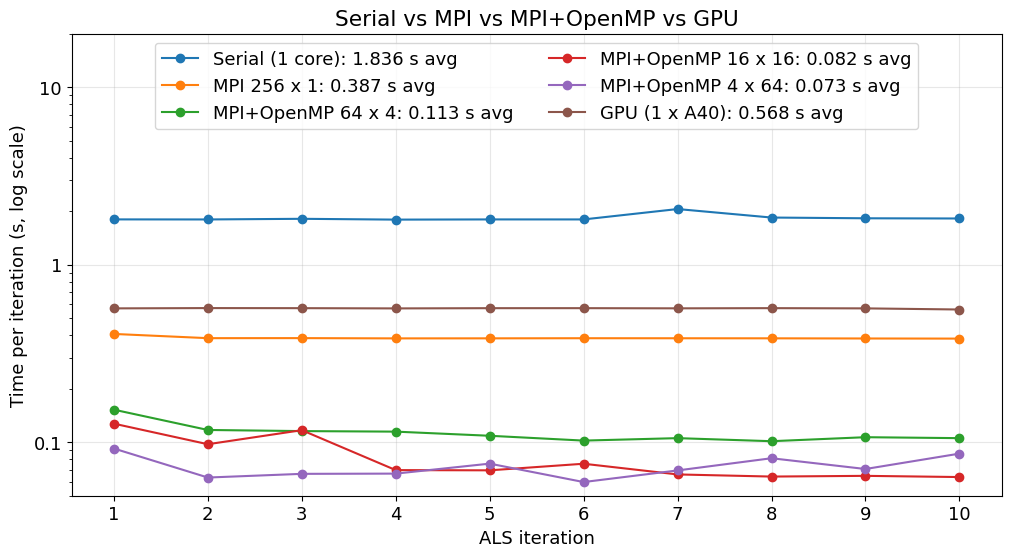

In [13]:
plt.rcParams.update({"font.size": 13})

# one line per version: (legend name, which rows)
versions = [
    ("Serial (1 core)",        df["experiment"] == "serial baseline"),
    ("MPI 256 x 1",            (df["experiment"] == "strong scaling") & (df["mpi_ranks"] == 256)),
    ("MPI+OpenMP 64 x 4",      (df["program"] == "MPI + OpenMP") & (df["mpi_ranks"] == 64)),
    ("MPI+OpenMP 16 x 16",     (df["program"] == "MPI + OpenMP") & (df["mpi_ranks"] == 16)),
    ("MPI+OpenMP 4 x 64",      (df["program"] == "MPI + OpenMP") & (df["mpi_ranks"] == 4)),
    ("GPU (1 x A40)",     df["experiment"] == "GPU test"),
]

plt.figure(figsize=(12, 6))
for name, rows in versions:
    d = df[rows].sort_values("iteration")
    avg = d["iter_time_s"].mean()
    plt.plot(d["iteration"], d["iter_time_s"], marker="o", label=f"{name}: {avg:.3f} s avg")

plt.yscale("log")
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))   # 0.1, 1 instead of 10^-1
plt.xticks(range(1, 11))
plt.xlabel("ALS iteration")
plt.ylabel("Time per iteration (s, log scale)")
plt.title("Serial vs MPI vs MPI+OpenMP vs GPU")
plt.ylim(0.05, 20)
plt.legend(loc="upper center", ncol=2, frameon=True)
plt.grid(True, alpha=0.3)
#plt.savefig("variants_comparison.png", dpi=200, bbox_inches="tight")
plt.show()